![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# Soil Heat Flux, Roughness and Aerodynamic Resistance

After net radiation, two more pieces are needed before a model can solve for evapotranspiration.
The soil heat flux `G` takes part of the net radiation into the ground, so it is not available for
evaporation. The sensible heat flux `H = rho cp dT / rah` depends on how easily heat is carried
from the surface into the air, which is expressed as an aerodynamic resistance `rah`. That
resistance depends on wind, on the roughness of the surface and on how the air's own buoyancy
helps or hinders turbulence (atmospheric stability). This notebook estimates `G` with the SEBAL
and METRIC formulas, builds roughness maps from LAI, NDVI and crop type, follows the wind from the
200 m blending height to the surface, and shows with a small experiment why stability corrections
can change `H` by a factor of two to three.

## Overview

### Soil heat flux

`G` is largest over bare, dark, hot soil in full sun and small under a dense canopy, which shades
the ground. Satellite models estimate the ratio `G/Rn` from vegetation and temperature:

| Model | Formula |
|---|---|
| SEBAL (Bastiaanssen 2000) | `G/Rn = (Ts - 273.15) (0.0038 albedo + 0.0074 albedo^2) (1 - 0.98 NDVI^4) / albedo` |
| METRIC (Tasumi 2003), LAI of at least 0.5 | `G/Rn = 0.05 + 0.18 exp(-0.521 LAI)` |
| METRIC, LAI below 0.5 | `G/Rn = 1.80 (Ts - 273.15) / Rn + 0.084` |
| Water | `G/Rn` about 0.5 for clear water in midday (heat stored in the water column) |

The ratios apply around midday; over a whole day `G` is close to zero, which is why daily ET uses
`Rn - G` only at the instant of the image.

### Wind near the surface

Under neutral conditions wind increases with the logarithm of height:

`u(z) = (u* / k) ln((z - d) / zom)`

`u*` is the **friction velocity** (the shear the surface exerts), `k = 0.41` the von Karman
constant, `zom` the **momentum roughness length** (roughly 1/8 of the canopy height) and `d` the
displacement height (about 2/3 of the canopy height). At a **blending height** of about 200 m the
wind is assumed to be the same over every surface in the scene, so wind measured at one weather
station is extended to 200 m with the station's grass roughness and brought back down over each
pixel with that pixel's `zom`.

### Aerodynamic resistance and the METRIC trick

Heat is carried from the surface by turbulence with a resistance

`rah = (ln(z2 / z1) - psi_h(z2) + psi_h(z1)) / (u* k)`

SEBAL and METRIC evaluate it between two heights above the zero plane displacement, `z1 = 0.1 m`
and `z2 = 2 m`, and define `dT` as the temperature difference between those heights, not between
the surface and the air. This sidesteps two unknowns: the roughness length for heat (`zoh`, much
smaller than `zom` and poorly known) and the difference between radiometric and aerodynamic
temperature. The calibration of `dT` at the anchors (notebook 05) absorbs them.

### Stability

When the surface is much hotter than the air, rising warm air enhances turbulence (**unstable**
conditions, typical of dry land at midday): `rah` falls and `H` rises. When the surface is cooler
than the air (irrigated crops under hot air), turbulence is damped (**stable**): `rah` rises. The
Monin-Obukhov length

`L = -rho cp u*^3 Ts / (k g H)`

measures the balance between shear and buoyancy. Negative `L` is unstable, positive stable,
infinite neutral. The corrections `psi_m` and `psi_h` follow Paulson (1970) for unstable and Webb
(1970) for stable air. Because `L` depends on `H` and `H` on `rah`, they are solved by iteration.

## Soil Heat and Aerodynamics with GeoLattice

| Function | Purpose |
|---|---|
| `seb.soil_heat_flux(rn, lst, albedo, ndvi, method=)` | `G` with the SEBAL (`"bastiaanssen"`) or METRIC (`"metric"`) formula |
| `seb.momentum_roughness(lai=, ndvi=, height=, landcover=, table=)` | `zom` from LAI, NDVI, canopy height or a land cover table |
| `seb.wind_at_blending_height`, `seb.wind_2m` | wind profiles |
| `seb.friction_velocity`, `seb.aerodynamic_resistance` | `u*` and `rah` |
| `seb.monin_obukhov_length`, `seb.stability_corrections` | stability |

### Learning objectives

1. Compute `G` with the SEBAL and METRIC formulas and explain where they differ.
2. Describe the log wind profile, roughness length, displacement height and blending height.
3. Build roughness maps from LAI, NDVI and crop type, and see how they change `rah`.
4. Explain why METRIC evaluates `rah` between 0.1 and 2 m.
5. Iterate `H`, the Monin-Obukhov length and the stability corrections, and quantify their effect.

### Data

The 5 July 2024 Landsat 8 scene of the Westside San Joaquin Valley with its crop map and ERA5
weather (`sd.load_scene`), and the radiation terms of notebook 03 (`sd.energy_inputs`).

### Contents

- Setup
- Soil heat flux
- The wind profile and the blending height
- Roughness length
- Friction velocity and aerodynamic resistance
- Stability: a numerical experiment
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

ds = sd.load_scene()  # Landsat 8, 5 July 2024
p = sd.energy_inputs(ds)  # NDVI, LAI, albedo, Rn and the other inputs of notebook 03
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().dropna()  # one row per pixel
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## Soil heat flux

,Rn,G_sebal,G_metric,ratio_sebal,ratio_metric,lai
Tree crops,566.38,125.85,99.20,0.23,0.18,1.20
Grapes,554.06,109.20,68.65,0.20,0.13,2.34
Annual crops,519.13,110.76,87.61,0.22,0.18,2.41
Fallow,484.50,145.67,144.02,0.30,0.30,0.04
Grass and shrubs,478.40,142.31,138.95,0.30,0.29,0.22
Developed,501.42,140.90,133.34,0.28,0.27,0.24


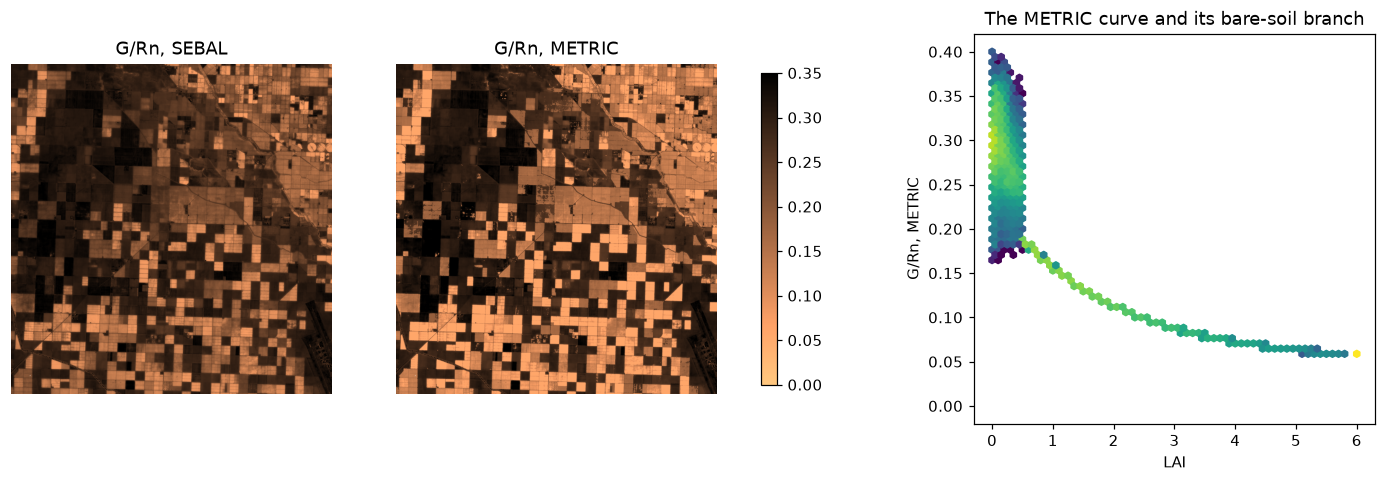

In [2]:
g_sebal = seb.soil_heat_flux(p["rn"], p["lst"], p["albedo"], p["ndvi"], method="bastiaanssen")  # SEBAL
g_metric = seb.soil_heat_flux(p["rn"], p["lst"], lai=p["lai"], method="metric", ndvi_=p["ndvi"])  # METRIC
display(by_group(Rn=p["rn"], G_sebal=g_sebal, G_metric=g_metric, ratio_sebal=g_sebal / p["rn"],
                 ratio_metric=g_metric / p["rn"], lai=p["lai"]).round(2))  # per crop group
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))  # three panels
for a, gg, t in zip(ax[:2], [g_sebal, g_metric], ["SEBAL", "METRIC"]):  # both maps
    im = a.imshow(gg / p["rn"], extent=ext, cmap="copper_r", vmin=0, vmax=0.35); a.set_title(f"G/Rn, {t}"); a.axis("off")  # ratio map
plt.colorbar(im, ax=ax[:2], shrink=0.8)  # shared scale
ax[2].hexbin(p["lai"].values.ravel(), (g_metric / p["rn"]).values.ravel(), gridsize=60, bins="log", extent=(0, 6, 0, 0.4))  # METRIC ratio vs LAI
ax[2].set_xlabel("LAI"); ax[2].set_ylabel("G/Rn, METRIC"); ax[2].set_title("The METRIC curve and its bare-soil branch")  # labels
plt.show()  # draw

Both formulas give `G/Rn` of 0.3 over fallow land and rangeland, and METRIC falls to about 0.06
at the LAI cap of 6. METRIC's bare-soil branch (LAI below 0.5) depends on surface temperature,
which shows as the vertical spread at LAI 0 in the scatter. The two formulas agree over fallow land
(144 and 146 W m-2) and disagree over vegetation, where SEBAL gives 27 to 41 W m-2 more (`G/Rn` of
0.20 to 0.23 against 0.13 to 0.18). Differences of that size in `G` pass straight into LE; the anchors calibrate them away only
at the two anchor pixels. The chapter uses the METRIC formula.

## The wind profile and the blending height

At the overpass ERA5 gives wind at 10 m. `seb.wind_2m` brings it to 2 m with the FAO-56 profile,
and `seb.wind_at_blending_height` extends it to 200 m over a grass weather station.

wind: 2.16 m/s at 10 m, 1.61 m/s at 2 m, 3.12 m/s at 200 m


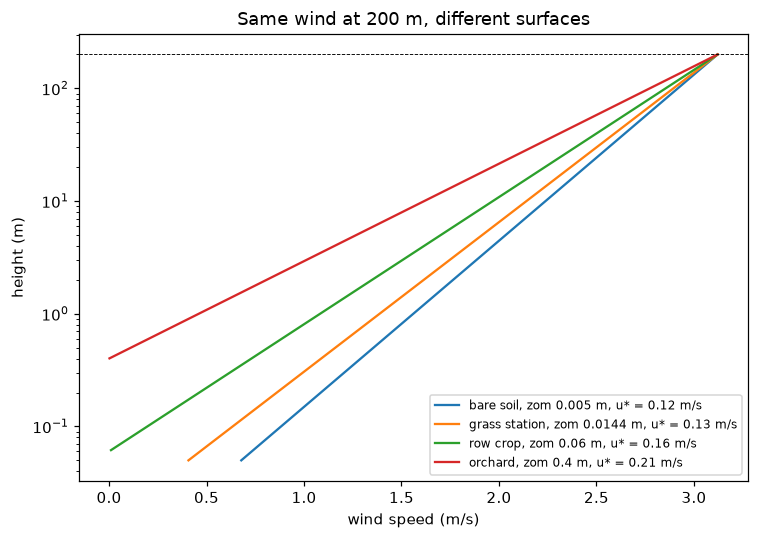

In [3]:
u10 = ds.attrs["u10"]; u2 = p["u2"]; u200 = p["u200"]  # ERA5 wind at 10 m, at 2 m, and at 200 m
k = seb.VON_KARMAN  # 0.41
print(f"wind: {u10:.2f} m/s at 10 m, {u2:.2f} m/s at 2 m, {u200:.2f} m/s at 200 m")  # the profile
z = np.geomspace(0.05, 200, 200)  # heights, m
fig, ax = plt.subplots(figsize=(7, 5))  # one panel
for zom, lab in [(0.005, "bare soil, zom 0.005 m"), (0.0144, "grass station, zom 0.0144 m"), (0.06, "row crop, zom 0.06 m"), (0.4, "orchard, zom 0.4 m")]:  # surfaces
    us = float(seb.friction_velocity(u200, 200.0, zom))  # neutral u* that gives the same wind at 200 m
    ax.plot(np.where(z > zom, us / k * np.log(z / zom), np.nan), z, label=f"{lab}, u* = {us:.2f} m/s")  # log profile
ax.set_yscale("log"); ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel("height (m)")  # axes
ax.axhline(200, color="k", lw=0.6, ls="--"); ax.legend(fontsize=8); ax.set_title("Same wind at 200 m, different surfaces")  # labels
plt.tight_layout(); plt.show()  # draw

All profiles meet at 200 m. A rough orchard slows the wind near the ground more, but its
friction velocity, the turbulent mixing that carries heat, is 1.75 times that of bare soil (0.21
against 0.12 m/s).
That is why rough canopies transfer heat efficiently even with modest wind.

## Roughness length

Three common ways to map `zom`:

- **LAI** (METRIC, agricultural areas): `zom = 0.018 LAI`, at least 0.005 m.
- **NDVI** (SEBAL and geeSEBAL): `zom = exp(5.62 NDVI - 5.809)`.
- **Land cover table**: typical canopy heights per crop class and `zom = 0.123 h`. The heights
  below are illustrative values for mature crops in midsummer, not measurements.

In [4]:
HEIGHT = {75: 4.0, 204: 3.5, 76: 6.0, 211: 4.0, 212: 4.0, 217: 3.0, 69: 1.8, 54: 0.6, 2: 1.0, 1: 2.0,
          36: 0.5, 208: 0.3, 24: 0.1, 21: 0.1, 51: 0.4, 61: 0.05, 176: 0.2, 152: 0.5, 121: 1.0, 122: 2.0,
          123: 3.0, 124: 4.0}  # illustrative canopy heights (m); harvested wheat and barley are stubble
zom_lai = seb.momentum_roughness(lai=p["lai"])  # METRIC
zom_ndvi = seb.momentum_roughness(ndvi_=p["ndvi"], method="ndvi")  # SEBAL / geeSEBAL
zom_tab = seb.momentum_roughness(landcover=ds.cdl, table={c: 0.123 * h for c, h in HEIGHT.items()}).where(p["mask"])  # crop table
by_group(zom_lai=zom_lai, zom_ndvi=zom_ndvi, zom_table=zom_tab).round(3)  # m, per crop group

,zom_lai,zom_ndvi,zom_table
Tree crops,0.022,0.066,0.452
Grapes,0.042,0.126,0.221
Annual crops,0.045,0.122,0.072
Fallow,0.005,0.006,0.006
Grass and shrubs,0.006,0.011,0.025
Developed,0.007,0.013,0.262


The three methods disagree most over orchards: LAI and NDVI see partial canopies (LAI near 1.2)
and give 0.02 to 0.07 m, against 0.45 m from tree height, while tall trees in rows are aerodynamically rough. The METRIC manual
adds a Perrier function for tall, sparse canopies for this reason. For annual crops and bare soil
the methods are closer. The next section shows what these differences do to `rah`.

## Friction velocity and aerodynamic resistance

Under neutral conditions, `u* = k u200 / ln(200 / zom)` and `rah` between 0.1 and 2 m is
`ln(20) / (k u*)`.

,rah LAI,rah NDVI,rah crop table
Tree crops,54.0,48.0,35.0
Grapes,50.0,44.0,39.0
Annual crops,52.0,48.0,47.0
Fallow,60.0,59.0,59.0
Grass and shrubs,60.0,56.0,51.0
Developed,60.0,57.0,39.0


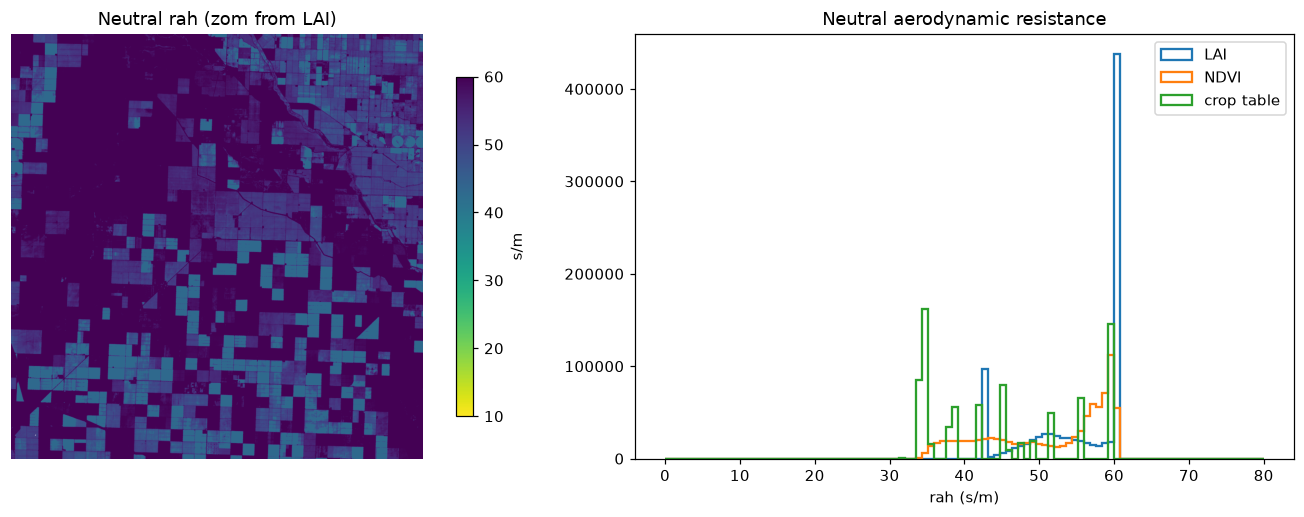

In [5]:
rah = {}  # neutral rah for each roughness map
for name, zz in [("LAI", zom_lai), ("NDVI", zom_ndvi), ("crop table", zom_tab)]:  # three roughness maps
    ustar = seb.friction_velocity(u200, 200.0, zz)  # m/s
    rah[name] = seb.aerodynamic_resistance(ustar, z1=0.1, z2=2.0)  # s/m
display(by_group(**{f"rah {n}": r for n, r in rah.items()}).round(0))  # per crop group, s/m
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))  # map and histogram
im = ax[0].imshow(rah["LAI"], extent=ext, cmap="viridis_r", vmin=10, vmax=60); plt.colorbar(im, ax=ax[0], shrink=0.8, label="s/m")  # rah map
ax[0].set_title("Neutral rah (zom from LAI)"); ax[0].axis("off")  # title
for n, r in rah.items():  # every roughness map
    ax[1].hist(r.values.ravel(), bins=100, range=(0, 80), histtype="step", lw=1.5, label=n)  # distribution
ax[1].set_xlabel("rah (s/m)"); ax[1].legend(); ax[1].set_title("Neutral aerodynamic resistance")  # labels
plt.tight_layout(); plt.show()  # draw

With about 3 m/s at 200 m, neutral `rah` is roughly 35 to 60 s/m: about 60 s/m over smooth fallow
land and down to 35 s/m over orchards with the crop-table roughness. For the same `dT`, a field
with `rah` of 35 s/m has 1.7 times the sensible heat of one with 60 s/m, so roughness is a
first-order input. In SEBAL and METRIC its
error is partly absorbed by the calibration of `dT`, which is computed with the same `rah` at the
anchors.

## Stability: a numerical experiment

The experiment holds the wind (3.1 m/s at 200 m) and roughness fixed and asks: for a given
temperature difference `dT` between 0.1 and 2 m, what is `H` under neutral assumptions and after
the Monin-Obukhov iteration? It repeats the inner loop of `seb.sensible_heat_iterative` without the
anchor calibration. `dT` stays below 10 K: at the hot anchor of this scene METRIC converges at
about 5 K, because `H` cannot exceed the available energy `Rn - G`.

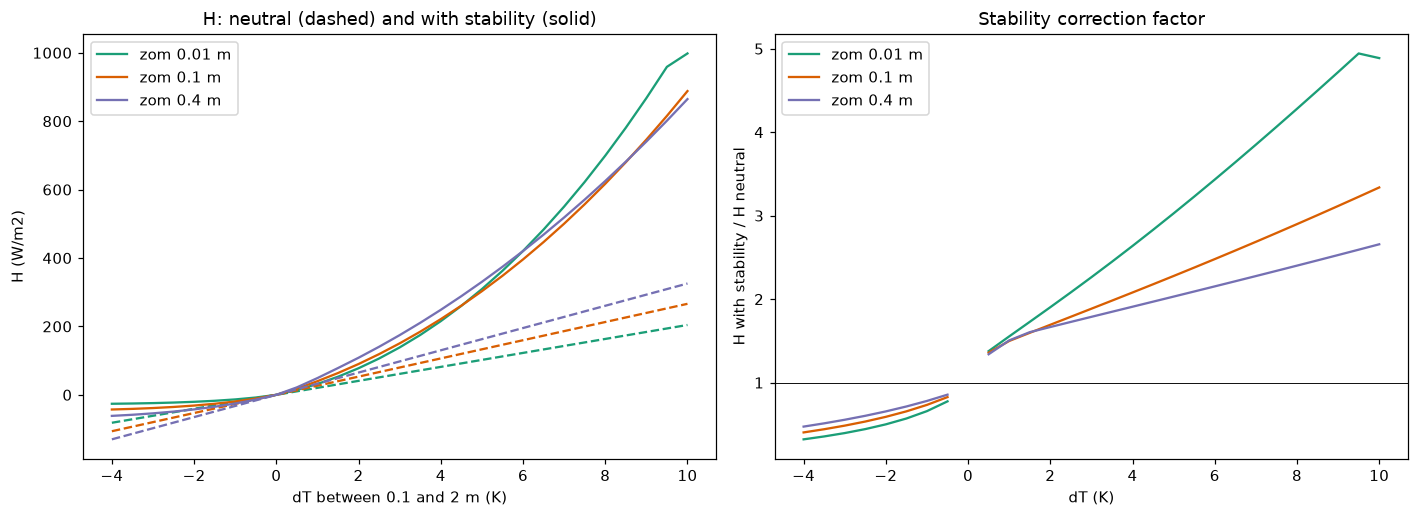

H neutral               H with stability                  rah            
zom       0.01   0.10   0.40             0.01   0.10   0.40   0.01  0.10  0.40
dT                                                                            
-2.0     -41.0  -53.0  -65.0            -20.0  -31.0  -43.0  106.0  69.0  51.0
 1.0      20.0   27.0   33.0             32.0   40.0   49.0   34.0  27.0  22.0
 2.0      41.0   53.0   65.0             78.0   90.0  108.0   28.0  24.0  20.0
 5.0     102.0  133.0  163.0            309.0  303.0  330.0   18.0  18.0  17.0
 8.0     163.0  213.0  260.0            699.0  617.0  625.0   13.0  14.0  14.0

In [6]:
def h_iterated(dT, zom, u_blend=u200, t_surface=320.0, pressure=100.5, n_iter=30):  # H for a fixed dT, with stability
    psi_m200 = psi_h2 = psi_h01 = 0.0  # start neutral
    rho = float(seb.air_density(pressure, t_surface - dT))  # air density, kg/m3
    for _ in range(n_iter):  # iterate H, L and the corrections
        ustar = seb.friction_velocity(u_blend, 200.0, zom, psi_m200)  # m/s
        rah_ = seb.aerodynamic_resistance(ustar, z1=0.1, z2=2.0, psi_h_z2=psi_h2, psi_h_z1=psi_h01)  # s/m
        h = rho * seb.CP * dT / rah_  # W/m2
        L = seb.monin_obukhov_length(rho, ustar, t_surface, h)  # m
        pm200, _ = seb.stability_corrections(200.0, L)  # momentum at 200 m (unstable)
        pm2, psi_h2 = seb.stability_corrections(2.0, L)  # heat at 2 m (and momentum at 2 m for stable air)
        _, psi_h01 = seb.stability_corrections(0.1, L)  # heat at 0.1 m
        psi_m200 = np.where(L < 0, pm200, pm2)  # METRIC uses 2 m for the stable momentum term
    return float(h), float(rah_), float(L)  # final values


dts = np.arange(-4, 10.5, 0.5)  # dT from -4 K (stable) to 10 K (strongly unstable)
rows = []  # results
for zom in (0.01, 0.1, 0.4):  # smooth, medium, rough
    for dT in dts:  # every temperature difference
        h_n = 1.15 * seb.CP * dT / float(seb.aerodynamic_resistance(seb.friction_velocity(u200, 200.0, zom)))  # neutral H
        h_s, r_s, L = h_iterated(dT, zom)  # with stability
        rows.append({"zom": zom, "dT": dT, "H neutral": h_n, "H with stability": h_s, "rah": r_s, "L": L})  # one row
exp = pd.DataFrame(rows)  # all cases
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))  # two panels
for zom, c in zip((0.01, 0.1, 0.4), ["#1b9e77", "#d95f02", "#7570b3"]):  # each roughness
    e = exp[exp.zom == zom]  # its cases
    ax[0].plot(e.dT, e["H neutral"], "--", color=c); ax[0].plot(e.dT, e["H with stability"], "-", color=c, label=f"zom {zom} m")  # H curves
    ax[1].plot(e.dT, e["H with stability"] / e["H neutral"].where(e.dT != 0), color=c, label=f"zom {zom} m")  # ratio
ax[0].set_xlabel("dT between 0.1 and 2 m (K)"); ax[0].set_ylabel("H (W/m2)"); ax[0].legend(); ax[0].set_title("H: neutral (dashed) and with stability (solid)")  # labels
ax[1].axhline(1, color="k", lw=0.6); ax[1].set_xlabel("dT (K)"); ax[1].set_ylabel("H with stability / H neutral"); ax[1].legend()  # labels
ax[1].set_title("Stability correction factor"); plt.tight_layout(); plt.show()  # draw
exp[exp.dT.isin([-2, 1, 2, 5, 8])].pivot(index="dT", columns="zom", values=["H neutral", "H with stability", "rah"]).round(0)  # table

Below 1 K the corrections are modest. At the `dT` of a hot anchor (about 5 K), unstable air
lowers `rah` and raises `H` to about three times the neutral estimate over smooth surfaces, less
over rough ones, which are already well mixed. This matches what SEBAL and METRIC do at their hot
pixels: in the notebook 00 run of this scene, `rah` at the hot anchor fell from 60 s/m (neutral)
to 17 s/m. With negative `dT` (a surface cooler than the air) stable conditions damp `H` and raise
`rah`.
Leaving stability out would bias the hot anchor, and through the calibration every pixel. Notebook
05 runs the same loop inside SEBAL, where `dT` itself is recalibrated at every iteration.

## Summary and exercises

- `G/Rn` is about 0.3 over hot bare soil and below 0.1 under dense crops; the SEBAL and METRIC
  formulas differ most over partial canopies.
- Wind measured at a station is carried to a 200 m blending height and back down over each pixel's
  roughness; an orchard has about 1.75 times the friction velocity of bare soil.
- LAI, NDVI and crop-table roughness disagree most over orchards, which LAI and NDVI see as
  partial canopies.
- METRIC's `rah` between 0.1 and 2 m avoids the roughness length for heat and the radiometric
  versus aerodynamic temperature problem; the anchor calibration absorbs them.
- Neutral `rah` between 0.1 and 2 m was 35 to 60 s/m. Stability corrections raise `H` about
  threefold at a hot anchor's `dT` of 5 K over smooth surfaces and must be iterated.

**Exercises**

1. Recompute `G` with `method="bastiaanssen"` and `method="metric"` for the 8 April scene. Where do
   the two disagree most early in the season?
2. Double the wind at 200 m and repeat the stability experiment. How does the correction factor
   change?
3. Replace the LAI roughness in `sd.energy_inputs` with the crop table roughness and run
   `sd.run_metric_scene`. How much do daily ET maps of orchards change?
4. Plot the Monin-Obukhov length of the experiment against `dT`. At what `dT` does `|L|` drop below
   2 m, the height of `z2`?